---
title: "Лабораторна робота 3. Структурне моделювання та аналіз складної мережі"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib
format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка
Лабораторна робота продовжує накопичувальний дослідницький артефакт:
$$
\text{Model Specification v0.1}\rightarrow
\text{Dynamic Model Specification v0.2}\rightarrow
\text{Network Model Specification v0.3}.
$$
ЛР3 спирається на першу частину Теми 5. Communities, modularity, assortativity та моделі random/small-world/scale-free networks свідомо залишаємо до Лекції 4.
:::

# Мета роботи
Набути практичної здатності формалізувати структуру взаємодій складної системи у вигляді мережевої моделі, обґрунтовувати семантику вузлів і ребер, будувати граф та матрицю суміжності, обчислювати базові структурні характеристики і формулювати коректні висновки з урахуванням невизначеності мережевої реконструкції.

# Завдання роботи
1. Сформулювати RQ, для якого структура взаємодій є суттєвою.
2. Визначити семантику вузлів і ребер.
3. Побудувати дві альтернативні мережеві операціоналізації одних даних.
4. Представити мережу як $G=(V,E)$ та матрицю $A$.
5. Перевірити базові інваріанти.
6. Обчислити degree, degree distribution, distances та clustering.
7. Порівняти centrality measures.
8. Відокремити topology від visual layout.
9. Провести простий експеримент із неповнотою ребер.
10. Сформувати *Network Model Specification v0.3*.

# Теоретичний мінімум
Мережева модель задається графом
$$
G=(V,E),
$$
де $V$ -- вузли, $E$ -- ребра [@newman2018; @barabasi2016].

Ключовий принцип:
$$
\boxed{\text{дані про взаємодії}\neq\text{мережева модель}}
$$
оскільки
$$
D\xrightarrow{\text{node/edge semantics}}G.
$$

## Логіка лабораторної роботи
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 D("Interaction<br/>data") --> RQ("Research<br/>Question")
 RQ --> S("Node / Edge<br/>semantics")
 S --> G("Graph<br/>G=(V,E)")
 G --> A("Adjacency<br/>matrix A")
 A --> M("Structural<br/>metrics")
 M --> U("Structural<br/>uncertainty")
 U --> I("Bounded<br/>interpretation")
```

# Частина I. Навчальний кейс
Розглянемо умовну онлайн-спільноту з вісьмома користувачами. Журнал містить `reply`, `mention`, `repost`.

RQ:
> *Як змінюється структурний опис онлайн-спільноти залежно від того, яке відношення між користувачами ми операціоналізуємо як ребро?*

# 1. Створення таблиці взаємодій

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

events = pd.DataFrame([
 ("u1","u2","reply"), ("u2","u1","reply"), ("u1","u3","mention"),
 ("u2","u3","reply"), ("u3","u1","reply"), ("u3","u2","mention"),
 ("u3","u4","reply"), ("u4","u3","reply"), ("u4","u5","mention"),
 ("u5","u4","reply"), ("u3","u6","repost"), ("u6","u3","repost"),
 ("u6","u7","reply"), ("u7","u6","reply"), ("u7","u8","mention"),
 ("u8","u7","reply"), ("u2","u4","mention"), ("u5","u6","mention"),
 ("u1","u2","mention"), ("u3","u4","mention")
], columns=["source","target","type"])
events

,source,target,type
0,u1,u2,reply
1,u2,u1,reply
2,u1,u3,mention
3,u2,u3,reply
4,u3,u1,reply
5,u3,u2,mention
6,u3,u4,reply
7,u4,u3,reply
8,u4,u5,mention
9,u5,u4,reply


# 2. Аудит даних перед побудовою графа
До `nx.from_pandas_edgelist(...)` потрібно встановити: що означає рядок; чи важливі повтори, напрямок і тип події; як агрегуються події; чи означає відсутність рядка відсутність реального зв'язку.

In [2]:
print("Кількість подій:", len(events))
print(events["type"].value_counts())
assert events[["source","target","type"]].notna().all().all()
assert (events["source"] != events["target"]).all()

Кількість подій: 20
type
reply      10
mention     8
repost      2
Name: count, dtype: int64


# 3. Дві мережеві операціоналізації
**Модель A:** ребро існує для `reply`.

**Модель B:** ребро існує для будь-якої спостережуваної взаємодії.

На цьому етапі обидві мережі неорієнтовані та незважені. Це модельне рішення.

In [3]:
users = sorted(set(events["source"]) | set(events["target"]))
reply_edges = events.loc[events["type"]=="reply",["source","target"]].drop_duplicates()
all_edges = events[["source","target"]].drop_duplicates()

G_reply = nx.Graph()
G_reply.add_nodes_from(users)
G_reply.add_edges_from(reply_edges.itertuples(index=False, name=None))

G_all = nx.Graph()
G_all.add_nodes_from(users)
G_all.add_edges_from(all_edges.itertuples(index=False, name=None))

print("G_reply:", G_reply.number_of_nodes(), "nodes,", G_reply.number_of_edges(), "edges")
print("G_all:", G_all.number_of_nodes(), "nodes,", G_all.number_of_edges(), "edges")

G_reply: 8 nodes, 7 edges
G_all: 8 nodes, 10 edges


## Завдання 3.1
Заповніть таблицю.

| Елемент | Модель A | Модель B |
|---|---|---|
| вузол | | |
| ребро | | |
| напрямок | | |
| вага | | |
| часовий інтервал | | |
| що ігнорується | | |
| яке RQ підтримує | | |

Поясніть, чому жодну модель не можна назвати «правильною» безвідносно до RQ.

# 4. Матриця суміжності
Побудуємо $A^{(reply)}$ та $A^{(all)}$ для однакового порядку вузлів.

In [4]:
A_reply = nx.to_numpy_array(G_reply, nodelist=users, dtype=int)
A_all = nx.to_numpy_array(G_all, nodelist=users, dtype=int)
print("A_reply")
display(pd.DataFrame(A_reply,index=users,columns=users))
print("A_all")
display(pd.DataFrame(A_all,index=users,columns=users))

A_reply


,u1,u2,u3,u4,u5,u6,u7,u8
u1,0,1,1,0,0,0,0,0
u2,1,0,1,0,0,0,0,0
u3,1,1,0,1,0,0,0,0
u4,0,0,1,0,1,0,0,0
u5,0,0,0,1,0,0,0,0
u6,0,0,0,0,0,0,1,0
u7,0,0,0,0,0,1,0,1
u8,0,0,0,0,0,0,1,0


A_all


,u1,u2,u3,u4,u5,u6,u7,u8
u1,0,1,1,0,0,0,0,0
u2,1,0,1,1,0,0,0,0
u3,1,1,0,1,0,1,0,0
u4,0,1,1,0,1,0,0,0
u5,0,0,0,1,0,1,0,0
u6,0,0,1,0,1,0,1,0
u7,0,0,0,0,0,1,0,1
u8,0,0,0,0,0,0,1,0


# 5. Перевірка структурних інваріантів
Для simple undirected graph:
$$
A=A^T,\qquad a_{ii}=0,\qquad \sum_i k_i=2|E|.
$$

In [5]:
def graph_sanity_checks(G, nodelist):
    A = nx.to_numpy_array(G,nodelist=nodelist,dtype=int)
    return {
      "symmetric_A": np.array_equal(A,A.T),
      "zero_diagonal": np.all(np.diag(A)==0),
      "degree_sum_equals_2E": sum(dict(G.degree()).values()) == 2*G.number_of_edges()
    }
print("G_reply:", graph_sanity_checks(G_reply,users))
print("G_all:", graph_sanity_checks(G_all,users))

G_reply: {'symmetric_A': True, 'zero_diagonal': np.True_, 'degree_sum_equals_2E': True}
G_all: {'symmetric_A': True, 'zero_diagonal': np.True_, 'degree_sum_equals_2E': True}


# 6. Степені вузлів
$$
k_i=\sum_j a_{ij}.
$$

In [6]:
degree_table = pd.DataFrame({
 "degree_reply": dict(G_reply.degree()),
 "degree_all": dict(G_all.degree())
})
degree_table["difference"] = degree_table["degree_all"]-degree_table["degree_reply"]
degree_table

,degree_reply,degree_all,difference
u1,2,2,0
u2,2,3,1
u3,3,4,1
u4,2,3,1
u5,1,2,1
u6,1,3,2
u7,2,2,0
u8,1,1,0


## Завдання 6.1
Знайдіть вузли, характеристики яких найбільше змінилися після зміни edge definition. Пояснюйте результат мовою операціоналізації, а не лише числами.

# 7. Розподіл степенів
$$
P(k)=\frac{N_k}{N}.
$$

In [7]:
def degree_distribution(G):
    d=pd.Series(dict(G.degree()),name="degree")
    z=d.value_counts().sort_index().rename("N_k").to_frame()
    z["P_k"]=z["N_k"]/G.number_of_nodes()
    return z
display(degree_distribution(G_reply))
display(degree_distribution(G_all))

,N_k,P_k
degree,,
1,3,0.375
2,4,0.500
3,1,0.125


,N_k,P_k
degree,,
1,1,0.125
2,3,0.375
3,3,0.375
4,1,0.125


::: callout-warning
## Методологічне застереження
Для мережі з восьми вузлів degree distribution є навчальною характеристикою. З нього не можна робити висновки про power law або scale-free structure [@newman2018; @barabasi2016].
:::

# 8. Зв'язність і компоненти
Перед average path length перевіряємо connectedness. Для різних компонент деякі $d(i,j)$ не є скінченними.

In [8]:
def connectivity_summary(G):
    cs=list(nx.connected_components(G))
    return {"connected":nx.is_connected(G),
            "n_components":nx.number_connected_components(G),
            "component_sizes":sorted([len(c) for c in cs],reverse=True)}
print("G_reply:",connectivity_summary(G_reply))
print("G_all:",connectivity_summary(G_all))

G_reply: {'connected': False, 'n_components': 2, 'component_sizes': [5, 3]}
G_all: {'connected': True, 'n_components': 1, 'component_sizes': [8]}


# 9. Відстані та середня довжина шляху
Для зв'язного графа
$$
L=\frac{1}{\binom{N}{2}}\sum_{i<j}d(i,j).
$$

In [9]:
def safe_average_path_length(G):
    if nx.is_connected(G):
        return nx.average_shortest_path_length(G)
    nodes=max(nx.connected_components(G),key=len)
    return nx.average_shortest_path_length(G.subgraph(nodes))
print("L_reply =",round(safe_average_path_length(G_reply),3))
print("L_all =",round(safe_average_path_length(G_all),3))

L_reply = 1.7
L_all = 2.071


## Завдання 9.1
Поясніть зміну $L$, причину скорочення шляхів після включення додаткових interaction types та чому менше $L$ не означає автоматично «кращу» систему.

# 10. Локальна кластеризація
$$
C_i=\frac{2e_i}{k_i(k_i-1)},\qquad k_i\ge2.
$$

In [10]:
clustering_table=pd.DataFrame({
 "C_reply":nx.clustering(G_reply),
 "C_all":nx.clustering(G_all)
})
clustering_table["difference"]=clustering_table["C_all"]-clustering_table["C_reply"]
clustering_table.round(3)

,C_reply,C_all,difference
u1,1.000,1.000,0.000
u2,1.000,0.667,-0.333
u3,0.333,0.333,0.000
u4,0.000,0.333,0.333
u5,0.000,0.000,0.000
u6,0.000,0.000,0.000
u7,0.000,0.000,0.000
u8,0.000,0.000,0.000


# 11. Глобальна кластеризація
Average clustering та transitivity мають різну нормалізацію. Не змішуйте їх під одним словом «кластеризація».

In [11]:
pd.DataFrame({
 "reply":{"average_clustering":nx.average_clustering(G_reply),"transitivity":nx.transitivity(G_reply)},
 "all":{"average_clustering":nx.average_clustering(G_all),"transitivity":nx.transitivity(G_all)}
}).round(3)

,reply,all
average_clustering,0.292,0.292
transitivity,0.429,0.333


# 12. Центральність -- операціоналізація структурної ролі
Порівнюємо degree, closeness і betweenness [@newman2018]:
$$
\text{many direct contacts}\neq
\text{structurally close}\neq
\text{bridge position}.
$$

In [12]:
centrality_all=pd.DataFrame({
 "degree":nx.degree_centrality(G_all),
 "closeness":nx.closeness_centrality(G_all),
 "betweenness":nx.betweenness_centrality(G_all)
})
centrality_all.round(3).sort_values("betweenness",ascending=False)

,degree,closeness,betweenness
u6,0.429,0.636,0.516
u3,0.571,0.636,0.413
u7,0.286,0.467,0.286
u4,0.429,0.500,0.103
u5,0.286,0.500,0.071
u2,0.429,0.500,0.040
u1,0.286,0.438,0.000
u8,0.143,0.333,0.000


## Завдання 12.1
Для двох вузлів із найбільшою betweenness поясніть їх структурне положення, порівняйте degree та betweenness і обґрунтуйте, чому «найважливіший вузол» без назви метрики -- некоректне твердження.

# 13. Стійкість centrality до network specification

In [13]:
comparison=pd.DataFrame({
 "degree_reply":nx.degree_centrality(G_reply),
 "degree_all":nx.degree_centrality(G_all),
 "between_reply":nx.betweenness_centrality(G_reply),
 "between_all":nx.betweenness_centrality(G_all)
})
comparison.round(3)

,degree_reply,degree_all,between_reply,between_all
u1,0.286,0.286,0.000,0.000
u2,0.286,0.429,0.000,0.040
u3,0.429,0.571,0.190,0.413
u4,0.286,0.429,0.143,0.103
u5,0.143,0.286,0.000,0.071
u6,0.143,0.429,0.000,0.516
u7,0.286,0.286,0.048,0.286
u8,0.143,0.143,0.000,0.000


## Завдання 13.1
Сформулюйте один *стійкий* і один *нестійкий* structural conclusion. Нестійкість є інформацією про structural uncertainty, а не просто «поганим результатом».

# 14. Візуалізація двох мереж
Для коректного порівняння використаємо однакові координати вузлів.

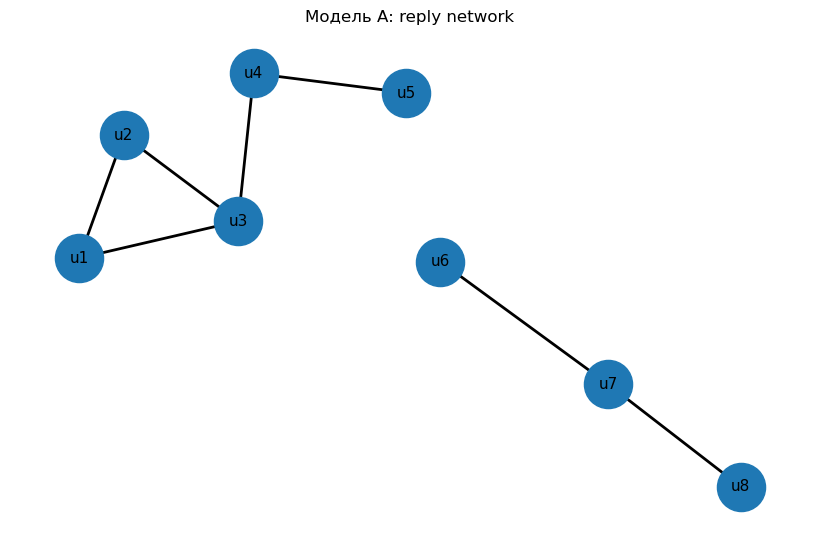

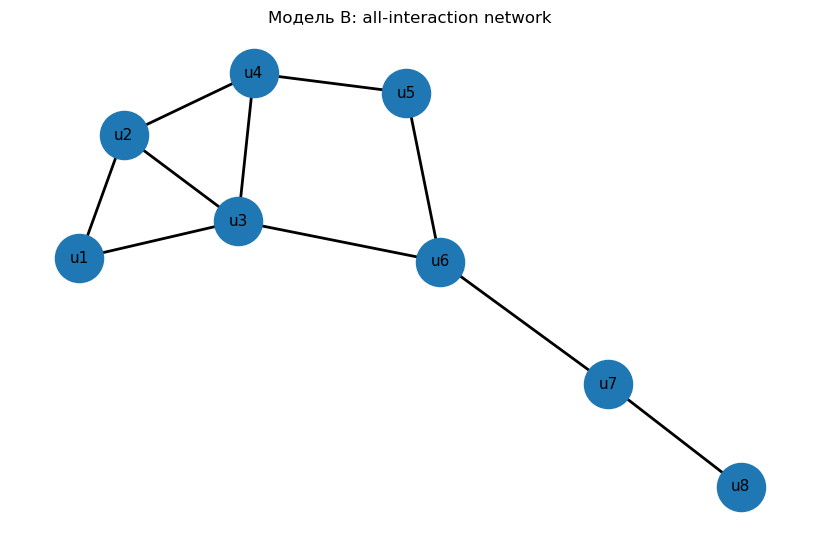

In [14]:
pos=nx.spring_layout(G_all,seed=42)
plt.figure(figsize=(8,5))
nx.draw(G_reply,pos,with_labels=True,node_size=1200,font_size=11,width=2)
plt.title("Модель A: reply network")
plt.show()

plt.figure(figsize=(8,5))
nx.draw(G_all,pos,with_labels=True,node_size=1200,font_size=11,width=2)
plt.title("Модель B: all-interaction network")
plt.show()

# 15. Layout не є топологією
Координати $z_i=(x_i,y_i)$, створені `spring_layout()`, не є частиною $G$, якщо просторове положення не задане предметною моделлю:
$$
\text{distance on figure}\neq d_G(i,j).
$$

# 16. Структурна невизначеність: неповні ребра
Вважатимемо $G_{all}$ умовно повною мережею і випадково приховаємо частину ребер.

::: callout-warning
## Увага
Це не повне UQ і не реалістична модель missingness. Це контрольована демонстрація того, що неповнота структури може змінити structural inference.
:::

In [15]:
def drop_edges_randomly(G,fraction=0.2,seed=42):
    rng=np.random.default_rng(seed)
    H=G.copy()
    edges=list(H.edges())
    n_drop=max(1,round(len(edges)*fraction))
    idx=rng.choice(len(edges),size=n_drop,replace=False)
    removed=[edges[i] for i in idx]
    H.remove_edges_from(removed)
    return H,removed

G_missing,removed_edges=drop_edges_randomly(G_all,0.20,42)
print("Видалені ребра:",removed_edges)

Видалені ребра: [('u1', 'u2'), ('u5', 'u6')]


In [16]:
u=pd.DataFrame({
 "betweenness_full":nx.betweenness_centrality(G_all),
 "betweenness_missing":nx.betweenness_centrality(G_missing)
})
u["absolute_change"]=(u["betweenness_missing"]-u["betweenness_full"]).abs()
u.round(3).sort_values("absolute_change",ascending=False)

,betweenness_full,betweenness_missing,absolute_change
u3,0.413,0.714,0.302
u4,0.103,0.286,0.183
u5,0.071,0.000,0.071
u2,0.040,0.000,0.040
u6,0.516,0.476,0.040
u1,0.000,0.000,0.000
u7,0.286,0.286,0.000
u8,0.000,0.000,0.000


## Завдання 16.1
Поясніть, які node roles змінилися, чи змінився ranking і чому це не означає, що реальна мережа змінилася:
$$
\text{неповне спостереження}
\rightarrow
\text{інший reconstructed graph}
\rightarrow
\text{інша metric}
\rightarrow
\text{можлива нестійкість inference}.
$$

# 17. Малий ансамбль реконструкцій
Один perturbation run може бути нетиповим. Повторимо процедуру для багатьох `seed`.

In [17]:
records=[]
for seed in range(200):
    H,_=drop_edges_randomly(G_all,0.20,seed)
    for node,value in nx.betweenness_centrality(H).items():
        records.append({"seed":seed,"node":node,"betweenness":value})
bc_ensemble=pd.DataFrame(records)
bc_summary=bc_ensemble.groupby("node")["betweenness"].agg(
    mean="mean",std="std",min="min",max="max"
)
bc_summary.round(3)

,mean,std,min,max
node,,,,
u1,0.009,0.033,0.0,0.286
u2,0.105,0.137,0.0,0.476
u3,0.358,0.213,0.0,0.762
u4,0.176,0.180,0.0,0.595
u5,0.111,0.179,0.0,0.571
u6,0.368,0.229,0.0,0.762
u7,0.153,0.140,0.0,0.286
u8,0.000,0.000,0.0,0.000


## Завдання 17.1
Порівняйте вузли за mean, std і min--max. Обґрунтуйте, чому твердження про стійкість structural role інформативніше за одне точкове значення centrality.

# 18. Критичний аудит навчального кейсу

| Питання | Відповідь |
|---|---|
| Яке RQ визначає мережеву модель? | |
| Що є вузлом? | |
| Що означає ребро? | |
| Чому граф неорієнтований? | |
| Чому ваги не використовуються? | |
| Яку інформацію втрачено під час агрегації? | |
| Яка предметна інтерпретація degree? | |
| Яка предметна інтерпретація betweenness? | |
| Що змінилося після іншого edge definition? | |
| Що змінилося через missing edges? | |
| Що можна стверджувати про граф? | |
| Що не можна стверджувати про реальну спільноту? | |

::: callout-tip
## Порада
Результат ЛР3 -- не «граф із метриками», а
$$
RQ\rightarrow\text{network semantics}\rightarrow G\rightarrow
\text{metric}\rightarrow\text{interpretation}\rightarrow
\text{uncertainty audit}.
$$
:::

# Частина II. Перенесення на дисертаційне дослідження
Спочатку дайте відповідь: *чи є структура вибіркових взаємодій суттєвою для мого RQ?* Якщо ні -- не потрібно штучно перетворювати систему на граф.

# 19. Обґрунтування мережевого представлення

| Питання | Відповідь |
|---|---|
| Яке RQ потребує network representation? | |
| Чому агрегована модель недостатня? | |
| Що є вузлом? | |
| Що є ребром? | |
| Directed / undirected? | |
| Weighted / unweighted? | |
| Що означає вага? | |
| Self-loops? | |
| Часовий інтервал агрегації? | |
| Чи є мережа статичною в межах експерименту? | |
| Які взаємодії залишаються поза моделлю? | |

# 20. Альтернативна операціоналізація
Сформулюйте щонайменше два допустимі визначення ребра $E^{(A)}$ та $E^{(B)}$ і поясніть, яке RQ підтримує кожне. Якщо природної альтернативи немає -- обґрунтуйте це.

# 21. Побудова мережі
Побудуйте $G=(V,E)$ і зафіксуйте джерело даних, формування $V$ і $E$, агрегацію, очищення, часові межі, фільтри та threshold.

::: callout-important
## Важливо
Між raw data та $G$ не повинно бути прихованих ручних операцій:
$$
D_{raw}\rightarrow D_{clean}\rightarrow E\rightarrow G.
$$
:::

# 22. Structural sanity checks
Виведіть перевірки з власної специфікації. Для simple undirected graph це можуть бути
$$
A=A^T,\qquad a_{ii}=0,\qquad \sum_i k_i=2|E|.
$$
Для directed/weighted graph набір має бути іншим.

# 23. Структурний профіль

| Рівень | Характеристика |
|---|---|
| network | $N=|V|$ |
| network | $M=|E|$ |
| network | density |
| network | number of components |
| network | average path length або GCC path length |
| network | average clustering |
| node | degree |
| node | closeness |
| node | betweenness |

Кожну метрику супроводьте предметною інтерпретацією.

# 24. Стійкість висновку до network specification
Порівняйте $G^{(A)}$ і $G^{(B)}$: що залишається, що змінюється, яке модельне рішення спричинило зміну і чи впливає це на відповідь на RQ.

# 25. Аудит неповноти структури
Визначте реальне джерело missing/uncertain edges та запропонуйте контрольований perturbation experiment. Повний UQ тут не потрібний.

# 26. Network Model Specification v0.3

| Компонент | Специфікація v0.3 |
|---|---|
| Research Question | |
| Причина використання network model | |
| Node semantics | |
| Edge semantics | |
| Directed / undirected | |
| Weighted / unweighted | |
| Weight semantics | |
| Temporal aggregation | |
| Self-loops | |
| Multiple edges / aggregation | |
| Data source | |
| Missing-edge mechanism | |
| Основні structural metrics | |
| Quantity / conclusion of interest | |
| Alternative network specification | |
| Structural uncertainty | |
| Обмеження інтерпретації | |

$$
\text{Dynamic Model Specification v0.2}
\rightarrow
\text{Network Model Specification v0.3}.
$$

# 27. Підсумковий артефакт ЛР3
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Dynamic Model<br/>Specification v0.2") --> B("Network<br/>semantics")
 B --> C("Graph<br/>G=(V,E)")
 C --> D("Structural<br/>profile")
 D --> E("Alternative<br/>specification")
 E --> F("Missing-edge<br/>experiment")
 F --> G("Network Model<br/>Specification v0.3")
```

# Контрольні питання
1. Чому interaction table ще не є network model?
2. Як RQ визначає node та edge semantics?
3. Чому з одних даних можна побудувати кілька коректних мереж?
4. Які властивості має $A$ для simple undirected graph?
5. Як пов'язані degree sum та $|E|$?
6. Що описує degree distribution?
7. Чому не слід робити висновок про scale-free structure з малої мережі?
8. Коли average shortest path length не можна обчислювати для всього графа?
9. Чим average clustering відрізняється від transitivity?
10. Чому degree та betweenness описують різні roles?
11. Чому «найважливіший вузол» без centrality definition некоректний?
12. Чому layout не є topology?
13. Як edge definition впливає на inference?
14. Що таке structural uncertainty?
15. Як missing edges можуть змінити centrality?
16. Чому один perturbation run недостатній?
17. Які твердження стосуються графа, а які -- реальної системи?
18. Коли від network representation краще відмовитися?

# Вимоги до звіту
У `.ipynb` мають бути:  

* RQ;  
* node/edge semantics;  
* дві network specifications;  
* graph та adjacency matrix;  
* sanity checks;  
* degree/distribution;
* connectivity/path analysis;
* clustering;
* centralities;
* visualization;
* structural-uncertainty experiment;  
* critical audit;  
* dissertation transfer;  
* *Network Model Specification v0.3*;  
* висновки.

::: callout-important
## Важливо
Оцінюється не кількість NetworkX-функцій, а
$$
\text{RQ}\rightarrow\text{formalization}\rightarrow G\rightarrow
\text{metric}\rightarrow\text{scientific interpretation}.
$$
:::

# Висновки
Дайте відповіді:  
1. Яку структуру представляє граф?  
2. Які properties стійкі до alternative edge definition?  
3. Які node roles залежать від centrality measure?  
4. Наскільки висновок стійкий до неповноти ребер?  
5. Що можна стверджувати про network model і чого не можна переносити на real system?  

# Джерела та корисні ресурси
Використовується спільна база `mmss-references.bib`.

- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References